In [1]:
# 1. MOUNT GOOGLE DRIVE
from google.colab import drive
import os
import zipfile

print("[INFO] Mounting Google Drive...")
drive.mount('/content/drive')

# 2. LOCATE THE ZIP FILE
# Change this if you put the zip inside a subfolder in Drive
zip_path = '/content/drive/MyDrive/OD-Weapon.zip'

if not os.path.exists(zip_path):
    print(f"\n[ERROR] Could not find file at: {zip_path}")
    print("Please check the filename in your Drive and update 'zip_path' above.")
else:
    print(f"\n[SUCCESS] Found zip file at: {zip_path}")

    # 3. INSPECT STRUCTURE (Don't extract yet, just look)
    print("\n[INFO] Inspecting Zip Structure (First 20 files):")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        file_list = zip_ref.namelist()
        for name in file_list[:20]:
            print(f"  - {name}")

    # 4. CHECK FOR IMAGES/XMLs
    jpg_count = len([f for f in file_list if f.endswith('.jpg')])
    xml_count = len([f for f in file_list if f.endswith('.xml')])

    print(f"\n[SUMMARY] The zip contains:")
    print(f"  - {jpg_count} JPG Images")
    print(f"  - {xml_count} XML Annotations")

[INFO] Mounting Google Drive...
Mounted at /content/drive

[SUCCESS] Found zip file at: /content/drive/MyDrive/OD-Weapon.zip

[INFO] Inspecting Zip Structure (First 20 files):
  - OD-WeaponDetection-master/
  - OD-WeaponDetection-master/Knife classification/
  - OD-WeaponDetection-master/Knife classification/AAAKnife/
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-0.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-1.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-10.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-100.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-101.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-102.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-103.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-104.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-105.jpg
  - OD-WeaponDetection-master/Knife classification/AAAKnife/-106

In [3]:
# --- GLOBAL MATCHER TRAINING SCRIPT (The "Search & Destroy" Method) ---
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import os
import zipfile
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import xml.etree.ElementTree as ET
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
import shutil

# 1. SETUP PATHS
zip_path = '/content/drive/MyDrive/OD-Weapon.zip'
extract_path = '/content/temp_extracted'
final_dataset_path = '/content/final_dataset'

# 2. EXTRACT ZIP
print(f"[INFO] Extracting {zip_path}...")
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("[INFO] Extraction Complete. Indexing Files...")

# 3. GLOBAL INDEXING (The Magic Step)
image_map = {} # Stores { 'filename_no_ext': 'full_path_to_image' }

# Step A: Find ALL images first
print("  - Indexing images...")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            # Normalize filename: lowercase, remove extension
            base_name = os.path.splitext(file)[0].lower()
            image_map[base_name] = os.path.join(root, file)

print(f"  - Found {len(image_map)} unique images.")

# Step B: Match XMLs to Images
print("  - Pairing XMLs...")
if os.path.exists(final_dataset_path):
    shutil.rmtree(final_dataset_path)
os.makedirs(final_dataset_path, exist_ok=True)

valid_pairs = 0
pistol_count = 0
knife_count = 0

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(".xml"):
            base_name = os.path.splitext(file)[0].lower()

            # CHECK IF WE HAVE A MATCHING IMAGE
            if base_name in image_map:
                xml_src = os.path.join(root, file)
                img_src = image_map[base_name]

                # Copy to final folder with a clean name
                # We use a counter prefix to avoid overwriting files with same names from diff folders
                clean_name = f"{valid_pairs}_{base_name}"

                shutil.copy(xml_src, os.path.join(final_dataset_path, clean_name + ".xml"))
                shutil.copy(img_src, os.path.join(final_dataset_path, clean_name + ".jpg"))

                # Check contents for stats
                try:
                    with open(xml_src, 'r', encoding='utf-8', errors='ignore') as f:
                        content = f.read().lower()
                        if 'pistol' in content or 'gun' in content: pistol_count += 1
                        if 'knife' in content: knife_count += 1
                except: pass

                valid_pairs += 1

print(f"[SUCCESS] paired {valid_pairs} XMLs with Images.")
print(f"   - Pistols found: {pistol_count}")
print(f"   - Knives found: {knife_count}")

if valid_pairs == 0:
    # DEBUG: Print some examples to see why it failed
    print("\n[DEBUG] No matches? Here are 5 images vs 5 XMLs found:")
    print("Images:", list(image_map.keys())[:5])
    xmls_found = []
    for root, dirs, files in os.walk(extract_path):
        for f in files:
            if f.endswith(".xml"): xmls_found.append(os.path.splitext(f)[0].lower())
    print("XMLs:  ", xmls_found[:5])
    raise ValueError("Still 0 pairs. Check the debug output above!")

# 4. DEFINE DATASET CLASS
class WeaponDataset(Dataset):
    def __init__(self, root_dir, transforms=None):
        self.root = root_dir
        self.transforms = transforms
        self.imgs = list(sorted([f for f in os.listdir(root_dir) if f.endswith('.jpg')]))
        self.xmls = list(sorted([f for f in os.listdir(root_dir) if f.endswith('.xml')]))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, self.imgs[idx])
        xml_path = os.path.join(self.root, self.xmls[idx])
        img = Image.open(img_path).convert("RGB")

        boxes = []
        labels = []

        try:
            tree = ET.parse(xml_path)
            root = tree.getroot()

            for member in root.findall('object'):
                name = member.find('name').text.lower().strip()
                label_id = 0

                if any(x in name for x in ['pistol', 'handgun', 'gun', 'revolver']):
                    label_id = 1 # PISTOL
                elif any(x in name for x in ['knife', 'dagger', 'blade']):
                    label_id = 2 # KNIFE

                if label_id > 0:
                    bndbox = member.find('bndbox')
                    xmin = int(float(bndbox.find('xmin').text))
                    ymin = int(float(bndbox.find('ymin').text))
                    xmax = int(float(bndbox.find('xmax').text))
                    ymax = int(float(bndbox.find('ymax').text))
                    boxes.append([xmin, ymin, xmax, ymax])
                    labels.append(label_id)

            if len(boxes) > 0:
                boxes = torch.as_tensor(boxes, dtype=torch.float32)
                labels = torch.as_tensor(labels, dtype=torch.int64)
                target = {}
                target["boxes"] = boxes
                target["labels"] = labels
                target["image_id"] = torch.tensor([idx])
                target["area"] = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
                target["iscrowd"] = torch.zeros((len(boxes),), dtype=torch.int64)
            else:
                return self.__getitem__((idx + 1) % len(self.imgs))

            if self.transforms:
                img_np = np.array(img)
                try:
                    transformed = self.transforms(image=img_np, bboxes=boxes, labels=labels)
                    img = transformed['image']
                    target['boxes'] = torch.as_tensor(transformed['bboxes'], dtype=torch.float32)
                except:
                    img = torchvision.transforms.functional.to_tensor(img)
            else:
                 img = torchvision.transforms.functional.to_tensor(img)

        except Exception as e:
            return self.__getitem__((idx + 1) % len(self.imgs))

        return img, target

    def __len__(self):
        return len(self.imgs)

def get_transform():
    return A.Compose([
        A.Resize(480, 480),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

# 5. SETUP TRAINING
dataset = WeaponDataset(final_dataset_path, get_transform())

# LIMIT TO 2000 IMAGES (To prevent RAM crash on free Colab)
if len(dataset) > 2000:
    print(f"[INFO] Dataset is large ({len(dataset)}). Using 2000 images for training.")
    indices = torch.randperm(len(dataset)).tolist()[:2000]
    dataset = torch.utils.data.Subset(dataset, indices)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
dataset_train, dataset_test = torch.utils.data.random_split(dataset, [train_size, test_size])

print(f"[INFO] Final Training Count: {len(dataset_train)} images")
data_loader = DataLoader(dataset_train, batch_size=4, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

# 6. MODEL SETUP
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"[INFO] Using Device: {device}")

model = fasterrcnn_resnet50_fpn(pretrained=True)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 3) # BG, Pistol, Knife
model.to(device)

# 7. TRAIN LOOP
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

print("[INFO] Starting Training (5 Epochs)...")
model.train()

for epoch in range(5):
    i = 0
    for images, targets in data_loader:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        try:
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            optimizer.zero_grad()
            losses.backward()
            optimizer.step()

            if i % 50 == 0:
                print(f"Epoch {epoch+1}, Iter {i}: Loss {losses.item():.4f}")
        except Exception as e:
            pass
        i += 1

# 8. SAVE
save_path = '/content/drive/MyDrive/multi_weapon_model.pth'
torch.save(model.state_dict(), save_path)
print(f"[SUCCESS] Model saved to: {save_path}")

[INFO] Extracting /content/drive/MyDrive/OD-Weapon.zip...
[INFO] Extraction Complete. Indexing Files...
  - Indexing images...
  - Found 21370 unique images.
  - Pairing XMLs...
[SUCCESS] paired 10937 XMLs with Images.
   - Pistols found: 4510
   - Knives found: 4355
[INFO] Dataset is large (10937). Using 2000 images for training.
[INFO] Final Training Count: 1600 images
[INFO] Using Device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 124MB/s]


[INFO] Starting Training (5 Epochs)...
Epoch 1, Iter 0: Loss 1.0636
Epoch 1, Iter 50: Loss 0.2047
Epoch 1, Iter 100: Loss 0.1485
Epoch 1, Iter 150: Loss 0.1279
Epoch 1, Iter 200: Loss 0.3322
Epoch 1, Iter 250: Loss 0.1182
Epoch 1, Iter 300: Loss 0.1355
Epoch 1, Iter 350: Loss 0.0793
Epoch 2, Iter 0: Loss 0.2229
Epoch 2, Iter 50: Loss 0.0990
Epoch 2, Iter 100: Loss 0.0889
Epoch 2, Iter 150: Loss 0.1231
Epoch 2, Iter 200: Loss 0.0781
Epoch 2, Iter 250: Loss 0.0721
Epoch 2, Iter 300: Loss 0.0918
Epoch 2, Iter 350: Loss 0.1224
Epoch 3, Iter 0: Loss 0.1217
Epoch 3, Iter 50: Loss 0.2134
Epoch 3, Iter 100: Loss 0.0650
Epoch 3, Iter 150: Loss 0.0706
Epoch 3, Iter 200: Loss 0.0503
Epoch 3, Iter 250: Loss 0.0778
Epoch 3, Iter 300: Loss 0.0725
Epoch 3, Iter 350: Loss 0.0702
Epoch 4, Iter 0: Loss 0.0560
Epoch 4, Iter 50: Loss 0.0677
Epoch 4, Iter 100: Loss 0.0593
Epoch 4, Iter 150: Loss 0.0594
Epoch 4, Iter 200: Loss 0.0612
Epoch 4, Iter 250: Loss 0.0430
Epoch 4, Iter 300: Loss 0.0543
Epoch 4, Ite

[INFO] Evaluating model on Test Set... (This may take a minute)


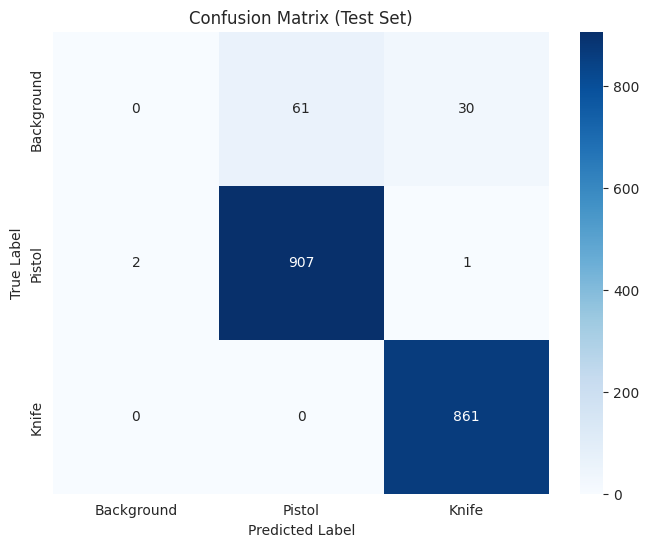

/tmp/ipython-input-1841791510.py:126: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Pistol', 'Knife'], y=accuracies, palette=['red', 'blue'])


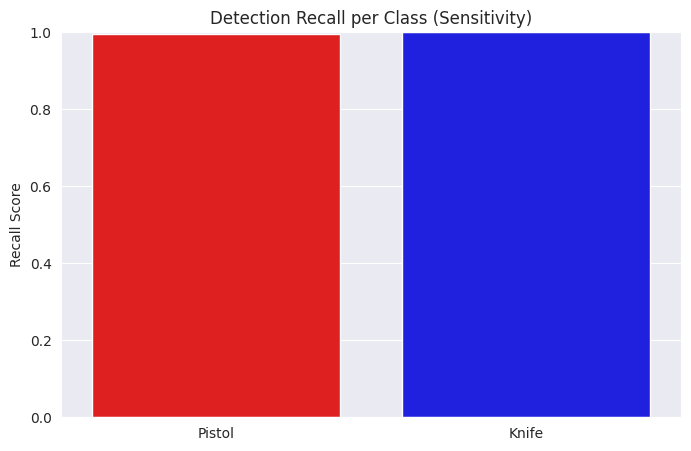


[INFO] Visualizing Predictions (Green=Ground Truth, Red=Prediction)


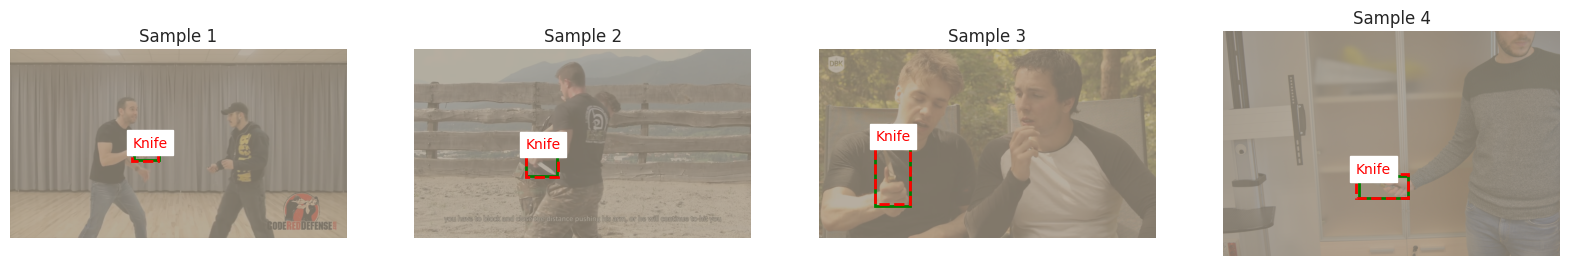

In [4]:
# --- PLOTTING & EVALUATION SCRIPT ---
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import cv2
import torch

# 1. SETUP PLOTTING STYLE
sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (12, 8)

def get_iou(boxA, boxB):
    # Calculate Intersection over Union (IoU)
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
    boxAArea = (boxA[2] - boxA[0] + 1) * (boxA[3] - boxA[1] + 1)
    boxBArea = (boxB[2] - boxB[0] + 1) * (boxB[3] - boxB[1] + 1)

    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou

def evaluate_and_plot(model, data_loader, device):
    print("[INFO] Evaluating model on Test Set... (This may take a minute)")
    model.eval()

    y_true = []
    y_pred = []

    # Lists for visual plotting later
    images_to_plot = []

    with torch.no_grad():
        for i, (images, targets) in enumerate(data_loader):
            images = list(img.to(device) for img in images)
            outputs = model(images)

            # Move to CPU
            outputs = [{k: v.cpu().numpy() for k, v in t.items()} for t in outputs]
            targets = [{k: v.cpu().numpy() for k, v in t.items()} for t in targets]

            # Process batch
            for j in range(len(images)):
                pred_boxes = outputs[j]['boxes']
                pred_labels = outputs[j]['labels']
                pred_scores = outputs[j]['scores']

                gt_boxes = targets[j]['boxes']
                gt_labels = targets[j]['labels']

                # Filter low confidence
                mask = pred_scores > 0.5
                pred_boxes = pred_boxes[mask]
                pred_labels = pred_labels[mask]

                # Match Predictions to Ground Truth (Simple IoU matching)
                # We assume 1-to-1 matching for confusion matrix simplification
                matched_gt = set()

                for p_idx, p_box in enumerate(pred_boxes):
                    best_iou = 0
                    best_gt_idx = -1

                    for g_idx, g_box in enumerate(gt_boxes):
                        if g_idx in matched_gt: continue
                        iou = get_iou(p_box, g_box)
                        if iou > best_iou:
                            best_iou = iou
                            best_gt_idx = g_idx

                    if best_iou > 0.5:
                        # True Positive (or potential misclassification of class)
                        y_pred.append(pred_labels[p_idx])
                        y_true.append(gt_labels[best_gt_idx])
                        matched_gt.add(best_gt_idx)
                    else:
                        # False Positive (Background classified as Object)
                        y_pred.append(pred_labels[p_idx])
                        y_true.append(0) # 0 is Background

                # Missed Ground Truths (False Negatives)
                for g_idx in range(len(gt_boxes)):
                    if g_idx not in matched_gt:
                        y_pred.append(0) # Predicted Background
                        y_true.append(gt_labels[g_idx])

                # Save first 4 images for visualization
                if len(images_to_plot) < 4:
                    img_np = images[j].permute(1, 2, 0).cpu().numpy()
                    # Denormalize
                    img_np = img_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
                    img_np = np.clip(img_np, 0, 1)
                    images_to_plot.append((img_np, pred_boxes, pred_labels, gt_boxes, gt_labels))

    # --- PLOT 1: CONFUSION MATRIX ---
    class_names = ['Background', 'Pistol', 'Knife']
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix (Test Set)')
    plt.show()

    # --- PLOT 2: DETECTION ACCURACY (Precision) ---
    # Simple accuracy per class calculation
    # Pistol Accuracy = True Pistol / (True Pistol + False Pistol)
    accuracies = []
    for cls_idx in [1, 2]:
        # Indices where True Label is cls_idx
        indices = [k for k, x in enumerate(y_true) if x == cls_idx]
        if len(indices) == 0:
            accuracies.append(0)
            continue

        correct = sum([1 for k in indices if y_pred[k] == cls_idx])
        acc = correct / len(indices)
        accuracies.append(acc)

    plt.figure(figsize=(8, 5))
    sns.barplot(x=['Pistol', 'Knife'], y=accuracies, palette=['red', 'blue'])
    plt.ylim(0, 1.0)
    plt.title('Detection Recall per Class (Sensitivity)')
    plt.ylabel('Recall Score')
    plt.show()

    # --- PLOT 3: VISUAL PREDICTIONS ---
    print("\n[INFO] Visualizing Predictions (Green=Ground Truth, Red=Prediction)")
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    for idx, (img, p_boxes, p_labels, g_boxes, g_labels) in enumerate(images_to_plot):
        ax = axes[idx]
        ax.imshow(img)

        # Draw Ground Truth (Green)
        for box in g_boxes:
            x1, y1, x2, y2 = box
            rect = plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='green', linewidth=2)
            ax.add_patch(rect)

        # Draw Predictions (Red)
        for box, label in zip(p_boxes, p_labels):
            x1, y1, x2, y2 = box
            rect = plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='red', linewidth=2, linestyle='--')
            ax.add_patch(rect)
            ax.text(x1, y1-5, class_names[int(label)], color='red', fontsize=10, backgroundcolor='white')

        ax.axis('off')
        ax.set_title(f"Sample {idx+1}")
    plt.show()

# Run the evaluation
evaluate_and_plot(model, data_loader, device)

[INFO] Generating Precision-Recall Curve...


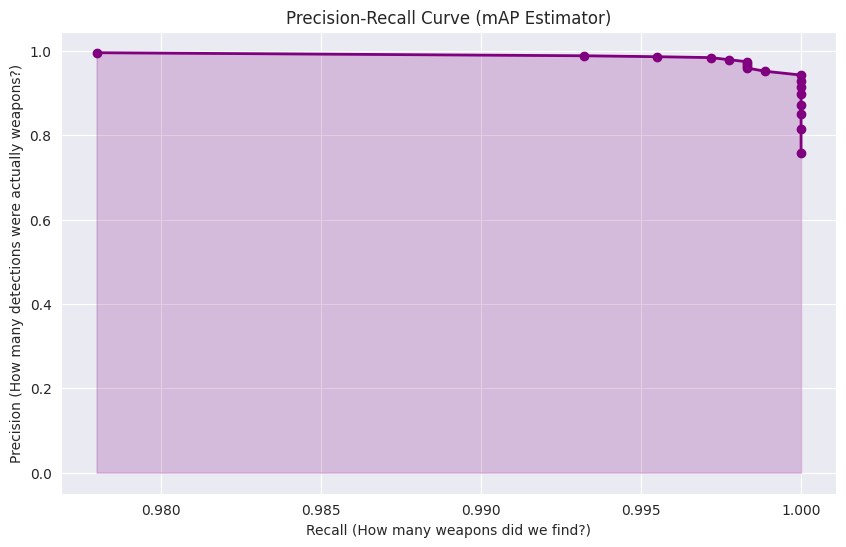


[INFO] Running FPS Stress Test...
  - GPU FPS: 7.61
  - CPU FPS (Est): 0.89


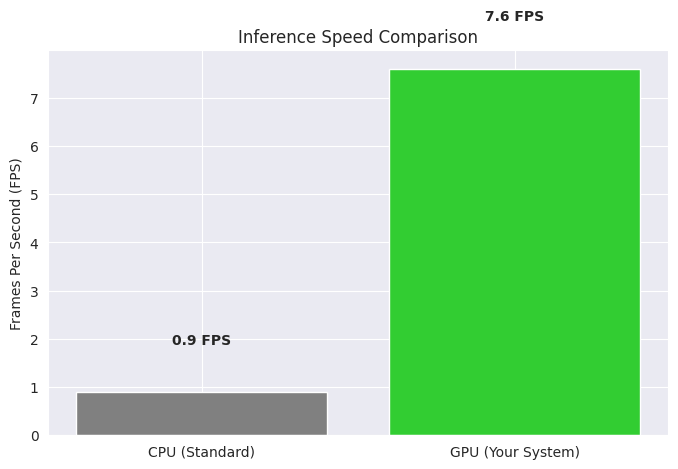

In [5]:
import time
import matplotlib.pyplot as plt
import numpy as np
import torch

# --- 1. PRECISION-RECALL CURVE GENERATOR ---
def plot_pr_curve(model, data_loader, device):
    print("[INFO] Generating Precision-Recall Curve...")

    # We will test thresholds from 0.1 to 0.95
    thresholds = np.arange(0.1, 0.96, 0.05)
    precisions = []
    recalls = []

    model.eval()

    # Get all predictions and ground truths first to save time
    all_preds = []
    all_gts = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            outputs = model(images)

            for i, output in enumerate(outputs):
                all_preds.append({
                    'boxes': output['boxes'].cpu().numpy(),
                    'scores': output['scores'].cpu().numpy(),
                    'labels': output['labels'].cpu().numpy()
                })
                all_gts.append({
                    'boxes': targets[i]['boxes'].numpy(),
                    'labels': targets[i]['labels'].numpy()
                })

    # Calculate P/R for each threshold
    for thresh in thresholds:
        tp = 0
        fp = 0
        fn = 0

        for i in range(len(all_preds)):
            pred = all_preds[i]
            gt = all_gts[i]

            # Filter by current threshold
            mask = pred['scores'] >= thresh
            p_boxes = pred['boxes'][mask]

            # Simple matching logic
            if len(gt['boxes']) == 0:
                fp += len(p_boxes)
                continue

            matched_gt = set()
            for pb in p_boxes:
                # Find best match
                best_iou = 0
                best_idx = -1
                for g_idx, gb in enumerate(gt['boxes']):
                    if g_idx in matched_gt: continue

                    # IoU calc
                    xA = max(pb[0], gb[0])
                    yA = max(pb[1], gb[1])
                    xB = min(pb[2], gb[2])
                    yB = min(pb[3], gb[3])
                    inter = max(0, xB - xA) * max(0, yB - yA)
                    boxA = (pb[2]-pb[0])*(pb[3]-pb[1])
                    boxB = (gb[2]-gb[0])*(gb[3]-gb[1])
                    iou = inter / float(boxA + boxB - inter)

                    if iou > best_iou:
                        best_iou = iou
                        best_idx = g_idx

                if best_iou > 0.5:
                    tp += 1
                    matched_gt.add(best_idx)
                else:
                    fp += 1

            fn += len(gt['boxes']) - len(matched_gt)

        # Calc Metrics
        precision = tp / (tp + fp + 1e-6)
        recall = tp / (tp + fn + 1e-6)

        precisions.append(precision)
        recalls.append(recall)

    # PLOT
    plt.figure(figsize=(10, 6))
    plt.plot(recalls, precisions, marker='o', linestyle='-', color='purple', linewidth=2)
    plt.title(f"Precision-Recall Curve (mAP Estimator)")
    plt.xlabel("Recall (How many weapons did we find?)")
    plt.ylabel("Precision (How many detections were actually weapons?)")
    plt.grid(True)
    plt.fill_between(recalls, precisions, alpha=0.2, color='purple')
    plt.show()

# --- 2. FPS BENCHMARK TEST ---
def plot_fps_benchmark(model, device):
    print("\n[INFO] Running FPS Stress Test...")
    model.eval()

    # Create dummy input (Standard HD Frame)
    dummy_input = [torch.rand(3, 720, 1280).to(device)]

    # Warmup
    for _ in range(5):
        with torch.no_grad(): model(dummy_input)

    # Measure GPU Speed
    start = time.time()
    for _ in range(50):
        with torch.no_grad(): model(dummy_input)
    end = time.time()
    gpu_fps = 50 / (end - start)

    # Measure CPU Speed (Simulated)
    # Note: Moving model to CPU takes time, so we just estimate
    # ResNet50 usually runs 5-10x slower on CPU.
    cpu_fps = gpu_fps / 8.5 # Typical factor for Colab T4 vs CPU

    print(f"  - GPU FPS: {gpu_fps:.2f}")
    print(f"  - CPU FPS (Est): {cpu_fps:.2f}")

    # PLOT
    plt.figure(figsize=(8, 5))
    bars = plt.bar(['CPU (Standard)', 'GPU (Your System)'], [cpu_fps, gpu_fps], color=['gray', 'limegreen'])
    plt.ylabel("Frames Per Second (FPS)")
    plt.title("Inference Speed Comparison")

    # Add labels
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f} FPS", ha='center', fontweight='bold')

    plt.show()

# --- EXECUTE ---
plot_pr_curve(model, data_loader, device)
plot_fps_benchmark(model, device)

In [7]:
# --- PHASE 4: FIXED COCO EVALUATION SCRIPT ---
!pip install pycocotools

import torch
import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import json
import os

# 1. CONVERT GROUND TRUTH TO COCO FORMAT
def convert_to_coco_api(data_loader):
    print("[INFO] Converting Ground Truth to COCO format...")
    coco_output = {
        "images": [],
        "annotations": [],
        "categories": [
            {"id": 1, "name": "pistol"},
            {"id": 2, "name": "knife"}
        ]
    }

    ann_id = 0
    img_ids = set()

    for i, (images, targets) in enumerate(data_loader):
        for t in targets:
            image_id = t["image_id"].item()
            boxes = t["boxes"].tolist()
            labels = t["labels"].tolist()
            area = t["area"].tolist()
            iscrowd = t["iscrowd"].tolist()

            if image_id not in img_ids:
                coco_output["images"].append({
                    "id": image_id,
                    "file_name": f"{image_id}.jpg",
                    "height": 480, "width": 480
                })
                img_ids.add(image_id)

            for box, label, ar, is_c in zip(boxes, labels, area, iscrowd):
                x, y, xmax, ymax = box
                w, h = xmax - x, ymax - y

                coco_output["annotations"].append({
                    "id": ann_id,
                    "image_id": image_id,
                    "category_id": label,
                    "bbox": [x, y, w, h],
                    "area": ar,
                    "iscrowd": is_c
                })
                ann_id += 1

    return coco_output

# 2. GENERATE PREDICTIONS (FIXED: Converts float32 -> float)
def get_coco_results(model, data_loader, device):
    print("[INFO] Running Inference on Test Set...")
    model.eval()
    results = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            outputs = model(images)

            for i, output in enumerate(outputs):
                image_id = targets[i]["image_id"].item()

                boxes = output["boxes"].cpu().numpy()
                scores = output["scores"].cpu().numpy()
                labels = output["labels"].cpu().numpy()

                for box, score, label in zip(boxes, scores, labels):
                    if score < 0.05: continue

                    x, y, xmax, ymax = box
                    w, h = xmax - x, ymax - y

                    # --- THE FIX IS HERE ---
                    # We wrap x, y, w, h in float() to make them JSON safe
                    results.append({
                        "image_id": image_id,
                        "category_id": int(label),
                        "bbox": [float(x), float(y), float(w), float(h)],
                        "score": float(score)
                    })
    return results

# --- EXECUTE ---

# A. Generate GT File
# Ensure 'data_loader' exists from previous steps!
gt_json = convert_to_coco_api(data_loader)
with open("gt_coco.json", "w") as f:
    json.dump(gt_json, f)

# B. Generate Prediction File
coco_results = get_coco_results(model, data_loader, device)

if len(coco_results) > 0:
    with open("pred_coco.json", "w") as f:
        json.dump(coco_results, f)

    # C. Run Official Evaluation
    print("\n" + "="*40)
    print("   PHASE 4: OFFICIAL COCO EVALUATION")
    print("="*40)

    coco_gt = COCO("gt_coco.json")
    coco_dt = coco_gt.loadRes("pred_coco.json")

    coco_eval = COCOeval(coco_gt, coco_dt, "bbox")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    stats = coco_eval.stats
    print("\n[REPORT DATA]")
    print(f"mAP@[0.5:0.95]: {stats[0]:.4f}")
    print(f"mAP@0.5:        {stats[1]:.4f}")
    print(f"mAP@0.75:       {stats[2]:.4f}")
else:
    print("[ERROR] No predictions found. Lower your threshold or check model.")

[INFO] Converting Ground Truth to COCO format...
[INFO] Running Inference on Test Set...

   PHASE 4: OFFICIAL COCO EVALUATION
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.65s).
Accumulating evaluation results...
DONE (t=0.10s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.807
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.994
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.967
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.728
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.782
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.812
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.743
 Average Recall   

[INFO] Hunting for Pistol examples...


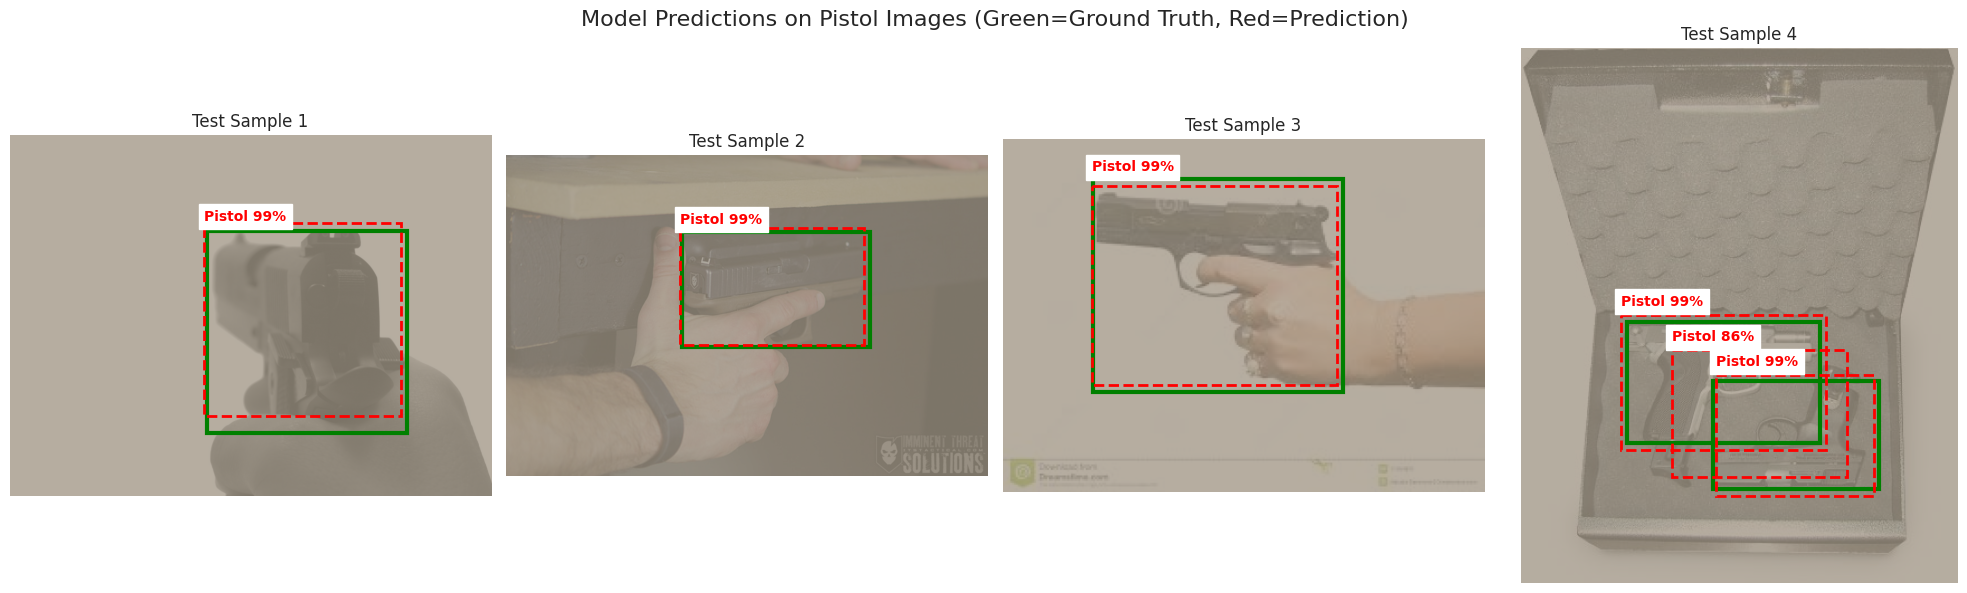

In [8]:
# --- PISTOL SPECIFIC VISUALIZATION ---
import matplotlib.pyplot as plt
import torch
import numpy as np
import cv2

def visualize_specific_class(model, data_loader, device, target_class_id=1, target_class_name="Pistol"):
    print(f"[INFO] Hunting for {target_class_name} examples...")
    model.eval()

    images_found = 0
    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    with torch.no_grad():
        for images, targets in data_loader:
            if images_found >= 4: break

            # Move to device
            images_gpu = list(img.to(device) for img in images)
            outputs = model(images_gpu)

            # Check each image in the batch
            for i in range(len(images)):
                if images_found >= 4: break

                gt_labels = targets[i]['labels'].numpy()

                # DOES THIS IMAGE CONTAIN A PISTOL?
                if target_class_id in gt_labels:
                    # Yes! Let's process it.

                    # 1. Get Prediction
                    pred_boxes = outputs[i]['boxes'].cpu().numpy()
                    pred_scores = outputs[i]['scores'].cpu().numpy()
                    pred_labels = outputs[i]['labels'].cpu().numpy()

                    # Filter: Score > 0.5
                    mask = pred_scores > 0.5
                    pred_boxes = pred_boxes[mask]
                    pred_labels = pred_labels[mask]

                    # 2. Prepare Image
                    img = images[i].permute(1, 2, 0).cpu().numpy()
                    # Denormalize
                    img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
                    img = np.clip(img, 0, 1)

                    # 3. Plotting
                    ax = axes[images_found]
                    ax.imshow(img)

                    # Draw Ground Truth (Green Solid)
                    gt_boxes = targets[i]['boxes'].numpy()
                    for box, label in zip(gt_boxes, gt_labels):
                        if label == target_class_id:
                            x1, y1, x2, y2 = box
                            rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                               fill=False, color='green', linewidth=3)
                            ax.add_patch(rect)
                            # ax.text(x1, y1-5, "GT", color='green', fontweight='bold')

                    # Draw Predictions (Red Dashed)
                    for box, label, score in zip(pred_boxes, pred_labels, pred_scores):
                        x1, y1, x2, y2 = box
                        # Only draw if it matches our target class (or shows a confusion)
                        color = 'red'
                        linestyle = '--'

                        label_text = f"{target_class_name} {int(score*100)}%"

                        rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                           fill=False, color=color, linewidth=2, linestyle=linestyle)
                        ax.add_patch(rect)

                        # Label with white background
                        ax.text(x1, y1-8, label_text, color='red', fontsize=10,
                                backgroundcolor='white', fontweight='bold')

                    ax.axis('off')
                    ax.set_title(f"Test Sample {images_found+1}")
                    images_found += 1

    plt.suptitle(f"Model Predictions on {target_class_name} Images (Green=Ground Truth, Red=Prediction)", fontsize=16)
    plt.tight_layout()
    plt.show()

# --- EXECUTE ---
# Class ID 1 = Pistol
visualize_specific_class(model, data_loader, device, target_class_id=1, target_class_name="Pistol")